# Assignment 4, Part 2: Mini Final Project
For our last assignment, please select and combine two geospatial datasets that are of interest to you. Explore, visualize, and analyze the data to tell us something about the area that we would not be able to determine from just one of these data sources alone. Please be sure to meet each of the following requirements in order to obtain full points. [35 points total]

* Select at least two *different* types of geospatial data. You may select any two from the following: point data, line data, polygon data, raster data. Data can be uploaded to the "data" folder here in Vocareum. [5 points] 
* Include a markdown cell that provides any relevant information about your data source (**where it came from, the area covered, features of interest, and any special considerations**). [2 points]
* Combine the data to tell us something new. Consider a spatial join between points and polygons or extracting raster values at specific point or polygon locations. [5 points]
* Include at least one visualization that shows both original datasets using the tips you have learned in this class for formatting nice looking maps. [5 points]
* Include at least one visualization that aggregates the data in some way. Consider a choropleth map or density map. [5 points]
* At least one of your visualizations must include a basemap. This can be one of the two required maps or, optionally, a third map. [3 points]
* Summarize your project and findings with a short write-up (at least three paragraphs) that describes the steps you took and the results of your analysis. This can be basic descriptive statistics, a statistical analysis, or a some machine learning application. Include the write-up at the end of the notebook as a markdown cell. [10 points]

This assignment will be manually graded by your instructor.

by: Randy Best

First I retrieved standings from [fussball.de](https://www.fussball.de), an open source website that has schedules, results and more content about soccer leagues in Germany (see ``wiki_scraper`` & ``write_scraped_df`` from ``utils`` to see how each table was scraped and archived). The ranking tables obtained consist of teams from the 1st to the 6th tier. Lower level teams are only selected from **Hessen**, a federal state in Germany. In total, there are 143 teams in the data collected. 69 polygon geometries remain after geocoding each club name using ``osmnx``. They represent the locations of soccer clubs from the standings DataFrame, but not all clubs could be geocoded because they are too low-key. Let's see how many teams play at a high level in Hessen, and observe the density of team across the state. The main feature of interest is the engineered (see ``concat_scrape`` from utils) "liga" feature, which means league in German.

The other geospatial data I gathered is from [The Regional Atlas](https://regionalatlas.statistikportal.de/) of the Federal and State Statistics Portal of Germany. The desired regional polygons can be selected at will and downloaded easily in ``.geojson`` format. This atlas will be used to clip according to region leaving 56 clubs in **Hessen**.

In [11]:
from utils import wiki_scraper, write_scraped_df, add_liga_col, concat_scrape
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# set crs, 
CRS = 5243
cached_geocoded_names = '../../assets/hessen_fussball_gdf.geojson'
regional_atlas = '../../assets/K-2024-AI014-1--AI1401--2026-11-20.geojson'
standings = 'bl_to_vl.csv'

In [ ]:
# load cached data and convert geocoded names to appropriate CRS
geocoded_names = gpd.read_file(cached_geocoded_names).to_crs(CRS)
geocoded_names['geometry'] = geocoded_names['geometry'].centroid
regions = gpd.read_file(regional_atlas).to_crs(CRS)
standings_df = pd.read_csv(standings)

# add tier column
tier_dict = {
    'verbandsliga_nord': 6,
    'verbandsliga_mitte': 6,
    'verbandsliga_sued': 6,
    'hessenliga': 5,
    'regionalliga_suedwest': 4,
    '3_bundesliga': 3,
    '2_bundesliga': 2,
    'bundesliga': 1,
}
standings_df['tier'] = [tier_dict[l] for l in standings_df['liga']]

# calculate areas of Germany and Hessen, clip & merge frames
hessen_region = regions[regions['schluessel'].str[:2] == '06']
print('Germany area:',round(sum(regions.area)/1000000),'square kilometers','\nHessen area:', round(sum(hessen_region.area)/1000000), 'square kilometers')
geocoded_names_hessen = geocoded_names.clip(hessen_region)
geo_standings_hessen = geocoded_names_hessen.merge(standings_df, on='mannschaft')

Germany area: 356886 kilometers 
Hessen area: 21079 kilometers


#### **Texas has 8 professional men's clubs**

695,662 square kilometers  
https://search.brave.com/search?q=texas+square+kilometers&source=web&conversation=09d544404eeb4ba403bbe70277339ef738f7

In [13]:
# geo_standings_hessen.explore(tooltip=False, popup=['mannschaft', 'tier', 'pl.platz.1'])

In [ ]:
clubs_join_regions = geo_standings_hessen.sjoin_nearest(hessen_region)

In [47]:
# number of bus stops in each neighborhood
clubs_by_region = clubs_join_regions.groupby('gen').count()[['mannschaft']].reset_index().rename(columns={'mannschaft': 'Club Count'})
clubs_per_region = hessen_region.merge(right=clubs_by_region, on='gen')

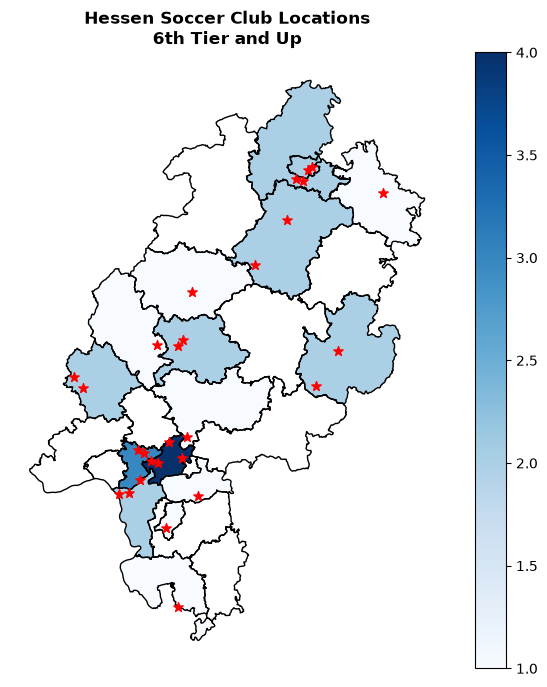

In [71]:
# https://medium.com/nerd-for-tech/labelling-areas-of-coordinates-with-geopandas-74d25c8aada6
# https://github.com/kylerod22/siads593-water-sustainability/blob/main/08-rjbest-sungmiki-kylerod-2026winter/src/PET_TA_EC_EDA.ipynb
clubs_per_region['coords'] = clubs_per_region['geometry'].apply(lambda x: x.representative_point().coords[:])
clubs_per_region['coords'] = [coords for coords in clubs_per_region['coords']]

fig, ax = plt.subplots(figsize=(8, 8))
hessen_region.plot(ax=ax, facecolor='none', zorder=2)
geo_standings_hessen.plot(ax=ax, markersize=50, zorder=3, color='red', marker='*')
# clubs_per_region.plot(ax=ax, zorder=1)

clubs_per_region.plot(
    ax=ax,
    column='Club Count',
    cmap='Blues',
    legend=True,
    # alpha=0.8,
    zorder=1
)

ax.axis('off')
plt.title('Hessen Soccer Club Locations\n6th Tier and Up', fontweight='bold');